# Wildfire Prediction — ResNet-50 (Iteration 0)

## Objective

Implement and evaluate a modified ResNet-50 architecture for
next-day wildfire ignition prediction in California using spatial
patches of environmental features.

This experiment investigates whether a deeper residual architecture
can improve predictive performance compared to the baseline CNN
and traditional machine learning models.

### Layer Freezing and Weight Initialization

- Pretrained weights: None
- Transfer learning: No
- Frozen layers: None
- Trainable parameters: 23,505,857 (100%)
- Training strategy: End-to-end training from scratch

All layers remain trainable throughout the training process,
allowing the network to learn domain-specific spatial
representations of environmental features for wildfire prediction.

In [ ]:
# Environment and GPU Verification

import sys
import numpy as np
import torch
import torchvision

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

assert torch.cuda.is_available(), "GPU is not available."

device = torch.device("cuda")

print("\nTraining device:", device)
print("GPU:", torch.cuda.get_device_name(0))

gpu_memory = torch.cuda.get_device_properties(0).total_memory

print(f"GPU memory: {gpu_memory / 1024**3:.2f} GB")

# Verify NumPy compatibility and GPU computation
x = np.ones((2, 9, 7, 7), dtype=np.float32)
tensor = torch.from_numpy(x).to(device)

print("GPU calculation:", tensor.mean().item())

print("\nEnvironment verification complete!")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.4.6
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130

Training device: cuda
GPU: Tesla T4
GPU memory: 14.56 GB
GPU calculation: 1.0

Environment verification complete!


In [ ]:
# Mount Google Drive

from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
# Locate Spatial Tensors

from pathlib import Path

drive_tensor_dir = Path("/content/drive/MyDrive/tensors")

expected_files = [
    "X_train.npy",
    "y_train.npy",
    "X_val.npy",
    "y_val.npy",
    "X_test.npy",
    "y_test.npy"
]

for filename in expected_files:
    path = drive_tensor_dir / filename

    assert path.exists(), f"Missing file: {path}"

    print(f"{filename}: {path.stat().st_size / 1e9:.4f} GB")

print("\nAll six tensor files located successfully!")

X_train.npy: 0.9836 GB
y_train.npy: 0.0022 GB
X_val.npy: 2.4500 GB
y_val.npy: 0.0056 GB
X_test.npy: 2.4570 GB
y_test.npy: 0.0056 GB

All six tensor files located successfully!


In [ ]:
# Copy Tensors to Local Runtime Storage

import shutil
import time

tensor_dir = Path("/content/tensors")
tensor_dir.mkdir(parents=True, exist_ok=True)

start = time.perf_counter()

for filename in expected_files:
    source = drive_tensor_dir / filename
    destination = tensor_dir / filename

    if (
        destination.exists()
        and destination.stat().st_size == source.stat().st_size
    ):
        print(f"Already copied: {filename}")
        continue

    print(f"Copying {filename}...")
    shutil.copy2(source, destination)

    assert destination.stat().st_size == source.stat().st_size

elapsed = time.perf_counter() - start

print(f"\nAll tensors copied in {elapsed:.2f} seconds.")

# Verify copied arrays
for split in ["train", "val", "test"]:
    X = np.load(tensor_dir / f"X_{split}.npy", mmap_mode="r")
    y = np.load(tensor_dir / f"y_{split}.npy", mmap_mode="r")

    assert X.shape[1:] == (9, 7, 7)
    assert len(X) == len(y)

    print(f"\n{split.upper()}")
    print("Features:", X.shape)
    print("Labels:", y.shape)

    del X, y

print("\nLocal tensors ready!")

Copying X_train.npy...
Copying y_train.npy...
Copying X_val.npy...
Copying y_val.npy...
Copying X_test.npy...
Copying y_test.npy...

All tensors copied in 98.36 seconds.

TRAIN
Features: (557616, 9, 7, 7)
Labels: (557616,)

VAL
Features: (1388899, 9, 7, 7)
Labels: (1388899,)

TEST
Features: (1392854, 9, 7, 7)
Labels: (1392854,)

Local tensors ready!


## Model Architecture — Modified ResNet-50

ResNet-50 is adapted from the PyTorch Torchvision implementation
to accommodate 9-channel, 7×7 spatial patches rather than
traditional RGB images.

### Architectural Modifications

- **Input:** 9 environmental feature channels with a 7×7 spatial window.
- **Initial convolution:** Modified to accept 9 channels using a
  3×3 kernel, stride of 1, and padding of 1.
- **Max pooling:** Removed to preserve spatial information.
- **Residual blocks:** Original ResNet-50 bottleneck configuration
  of [3, 4, 6, 3] retained.
- **Global average pooling:** Retained.
- **Fully connected layer:** Modified to produce a single output logit.
- **Output activation:** Sigmoid applied during evaluation.

### Architecture Summary

| Stage | Output Dimensions |
|---|---|
| Input | 9 × 7 × 7 |
| Initial Convolution | 64 × 7 × 7 |
| Residual Stage 1 | 256 × 7 × 7 |
| Residual Stage 2 | 512 × 4 × 4 |
| Residual Stage 3 | 1024 × 2 × 2 |
| Residual Stage 4 | 2048 × 1 × 1 |
| Global Average Pooling | 2048 |
| Fully Connected Layer | 1 |

### Weight Initialization and Freezing

- Pretrained weights: None
- Transfer learning: No
- Frozen layers: None
- Total parameters: 23,505,857
- Trainable parameters: 23,505,857

The entire network is trained from scratch because the input
represents environmental variables rather than conventional RGB images.

In [ ]:
# Modified ResNet-50 Architecture

import random
import torch.nn as nn
from torchvision.models import resnet50

SEED = 4337

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


class WildfireResNet50(nn.Module):

    def __init__(self):
        super().__init__()

        # ResNet-50 trained from scratch
        self.backbone = resnet50(weights=None)

        # Adapt to nine environmental input channels
        self.backbone.conv1 = nn.Conv2d(
            in_channels=9,
            out_channels=64,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False
        )

        # Preserve spatial information in 7x7 patches
        self.backbone.maxpool = nn.Identity()

        # Binary classification output
        self.backbone.fc = nn.Linear(
            self.backbone.fc.in_features,
            1
        )

    def forward(self, x):
        return self.backbone(x)


model = WildfireResNet50().to(device)

total_params = sum(p.numel() for p in model.parameters())

print(f"Total parameters: {total_params:,}")
print("Device:", device)

# Verify forward pass
model.eval()

dummy_input = torch.randn(8, 9, 7, 7).to(device)

with torch.no_grad():
    logits = model(dummy_input)

assert logits.shape == (8, 1)
assert torch.isfinite(logits).all().item()

print("Input shape:", dummy_input.shape)
print("Output shape:", logits.shape)

print("\nResNet-50 initialized successfully!")

Total parameters: 23,505,857
Device: cuda
Input shape: torch.Size([8, 9, 7, 7])
Output shape: torch.Size([8, 1])

ResNet-50 initialized successfully!


## Dataset and Spatial Representation

Each observation consists of a 7×7 spatial patch containing
nine environmental features from the previous day.

### Input Features

1. Temperature (t2m)
2. Relative Humidity (rh2m)
3. Wind Speed (wind_speed_10m)
4. Precipitation (tp)
5. Normalized Difference Vegetation Index (NDVI)
6. Enhanced Vegetation Index (EVI)
7. Elevation
8. Slope
9. Aspect

### Temporal Split

| Dataset | Year | Observations |
|---|---|---:|
| Training | 2022 | 557,616 |
| Validation | 2023 | 1,388,899 |
| Testing | 2024 | 1,392,854 |

The same preprocessed spatial tensors as the baseline CNN are
used to maintain consistency between architecture experiments.

The 2024 test set is excluded from training and model selection.

In [ ]:
# Spatial Dataset and DataLoaders

from torch.utils.data import Dataset, DataLoader


class MemoryMappedWildfireDataset(Dataset):

    def __init__(self, x_path, y_path):
        self.X = np.load(x_path, mmap_mode="r")
        self.y = np.load(y_path, mmap_mode="r")

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):

        x = torch.from_numpy(
            np.array(self.X[idx], dtype=np.float32, copy=True)
        )

        y = torch.tensor(
            [self.y[idx]], dtype=torch.float32
        )

        return x, y


train_dataset = MemoryMappedWildfireDataset(
    tensor_dir / "X_train.npy",
    tensor_dir / "y_train.npy"
)

val_dataset = MemoryMappedWildfireDataset(
    tensor_dir / "X_val.npy",
    tensor_dir / "y_val.npy"
)

batch_size = 256

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
    generator=generator
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

# Check class distribution
train_positives = int(train_dataset.y.sum())
train_negatives = len(train_dataset) - train_positives

val_positives = int(val_dataset.y.sum())
val_negatives = len(val_dataset) - val_positives

print("Training observations:", len(train_dataset))
print("Training positives:", train_positives)
print("Training negatives:", train_negatives)

print("\nValidation observations:", len(val_dataset))
print("Validation positives:", val_positives)
print("Validation negatives:", val_negatives)

print("\nBatch size:", batch_size)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

X_batch, y_batch = next(iter(train_loader))

assert torch.isfinite(X_batch).all().item()
assert ((y_batch == 0) | (y_batch == 1)).all().item()

print("\nFeature batch:", X_batch.shape)
print("Label batch:", y_batch.shape)

print("\nDataLoaders ready!")

Training observations: 557616
Training positives: 3608
Training negatives: 554008

Validation observations: 1388899
Validation positives: 3666
Validation negatives: 1385233

Batch size: 256
Training batches: 2179
Validation batches: 5426

Feature batch: torch.Size([256, 9, 7, 7])
Label batch: torch.Size([256, 1])

DataLoaders ready!


## Hardware Benchmark and Computational Optimization

The ResNet-50 architecture was initially tried and developed and verified
locally using Apple's MPS backend. Due to computational constraints,
full training was transferred to Google Colab using a Tesla T4 GPU.

| Metric | Local MPS | Colab Tesla T4 |
|---|---:|---:|
| Batch Size | 128 | 256 |
| Precision | FP32 | Mixed Precision |
| Estimated Time per Epoch | 106.16 min | 3.94 min |
| Estimated 50-Epoch Runtime | 88.47 hrs | 3.29 hrs |

The optimized Colab configuration provides an estimated 26.9×
speedup without reducing the training or validation datasets.

The benchmark configurations differ in batch size, precision,
and loss weighting, so this is an end-to-end computational
comparison rather than an isolated hardware comparison.

In [ ]:
# CUDA Mixed-Precision Training Benchmark

import time
import torch.optim as optim

# Address class imbalance using training distribution
pos_weight = torch.tensor(
    [train_negatives / train_positives],
    dtype=torch.float32,
    device=device
)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print("Positive class weight:", pos_weight.item())

# Temporary model to preserve original initialization
benchmark_model = WildfireResNet50().to(device)

benchmark_optimizer = optim.AdamW(
    benchmark_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

scaler = torch.amp.GradScaler("cuda")

num_batches = 50
warmup_batches = 5

# Training benchmark
benchmark_model.train()

for i, (X_batch, y_batch) in enumerate(train_loader):

    if i == warmup_batches:
        torch.cuda.synchronize()
        start = time.perf_counter()

    X_batch = X_batch.to(device, non_blocking=True)
    y_batch = y_batch.to(device, non_blocking=True)

    benchmark_optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16
    ):
        logits = benchmark_model(X_batch)
        loss = criterion(logits, y_batch)

    scaler.scale(loss).backward()
    scaler.step(benchmark_optimizer)
    scaler.update()

    if (i + 1) % 10 == 0:
        print(
            f"Training batch {i + 1}/"
            f"{num_batches + warmup_batches} | "
            f"Loss: {loss.item():.4f}"
        )

    if i + 1 == num_batches + warmup_batches:
        break

torch.cuda.synchronize()
train_elapsed = time.perf_counter() - start

# Validation benchmark
benchmark_model.eval()

with torch.inference_mode():

    for i, (X_batch, y_batch) in enumerate(val_loader):

        if i == warmup_batches:
            torch.cuda.synchronize()
            start = time.perf_counter()

        X_batch = X_batch.to(device, non_blocking=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = benchmark_model(X_batch)

        if i + 1 == num_batches + warmup_batches:
            break

torch.cuda.synchronize()
val_elapsed = time.perf_counter() - start

# Estimate training duration
train_per_batch = train_elapsed / num_batches
val_per_batch = val_elapsed / num_batches

train_minutes = train_per_batch * len(train_loader) / 60
val_minutes = val_per_batch * len(val_loader) / 60

epoch_minutes = train_minutes + val_minutes

print("\n--- T4 Benchmark Results ---")
print(f"Training batch: {train_per_batch:.4f} seconds")
print(f"Validation batch: {val_per_batch:.4f} seconds")
print(f"Training per epoch: {train_minutes:.2f} minutes")
print(f"Validation per epoch: {val_minutes:.2f} minutes")
print(f"Total per epoch: {epoch_minutes:.2f} minutes")

print(f"Estimated 10 epochs: {epoch_minutes * 10 / 60:.2f} hours")
print(f"Estimated 50 epochs: {epoch_minutes * 50 / 60:.2f} hours")

print(
    f"Peak GPU memory: "
    f"{torch.cuda.max_memory_allocated() / 1024**3:.2f} GB"
)

# Release temporary model
del benchmark_model, benchmark_optimizer, scaler
del logits, loss, X_batch, y_batch

torch.cuda.empty_cache()

print("\nBenchmark complete!")

Positive class weight: 153.54989624023438
Training batch 10/55 | Loss: 1.4970
Training batch 20/55 | Loss: 0.6642
Training batch 30/55 | Loss: 0.6373
Training batch 40/55 | Loss: 0.4854
Training batch 50/55 | Loss: 0.4955

--- T4 Benchmark Results ---
Training batch: 0.0768 seconds
Validation batch: 0.0128 seconds
Training per epoch: 2.79 minutes
Validation per epoch: 1.15 minutes
Total per epoch: 3.94 minutes
Estimated 10 epochs: 0.66 hours
Estimated 50 epochs: 3.29 hours
Peak GPU memory: 0.86 GB

Benchmark complete!


## Training Configuration

| Hyperparameter | Value |
|---|---|
| Random Seed | 4337 |
| Maximum Epochs | 50 |
| Batch Size | 256 |
| Optimizer | AdamW |
| Initial Learning Rate | 0.001 |
| Weight Decay | 0.0001 |
| Loss Function | Weighted Binary Cross-Entropy with Logits |
| Positive Class Weight | 153.5499 |
| LR Scheduler | ReduceLROnPlateau |
| LR Reduction Factor | 0.5 |
| LR Scheduler Patience | 3 epochs |
| Minimum Learning Rate | 0.000001 |
| Early Stopping Patience | 10 epochs |
| Model Selection | Adjusted Validation PR-AUC |
| Precision | FP16 Automatic Mixed Precision |
| Hardware | NVIDIA Tesla T4 |

### Class Imbalance

To address the severe imbalance between fire and non-fire
observations, the positive class weight is calculated as:

$$
w_{pos} = \frac{N_{negative}}{N_{positive}}
= \frac{554008}{3608}
\approx 153.55
$$

### Training Strategy

- Train all layers end-to-end using backpropagation.
- Shuffle training observations after each epoch.
- Evaluate the complete available validation tensor after each epoch.
- Reduce the learning rate when validation performance plateaus.
- Save the best model according to adjusted validation PR-AUC.
- Save resumable checkpoints to Google Drive after every epoch.
- Apply early stopping to limit unnecessary training and overfitting.

In [ ]:
# Final Training Configuration

import json
import random
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score
)

# Reset seeds after benchmarking
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

generator.manual_seed(SEED)

# Experiment configuration
config = {
    "model": "WildfireResNet50",
    "iteration": 0,
    "run": "run1_seeded",
    "seed": SEED,
    "epochs": 50,
    "batch_size": batch_size,
    "learning_rate": 0.001,
    "weight_decay": 0.0001,
    "pos_weight": train_negatives / train_positives,
    "early_stopping_patience": 10,
    "validation_negative_sample_fraction": 0.05,
    "optimizer": "AdamW",
    "scheduler": "ReduceLROnPlateau",
    "pretrained": False,
    "mixed_precision": True,
    "training_samples": len(train_dataset),
    "validation_samples": len(val_dataset),
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__,
    "numpy_version": np.__version__
}

run_name = "resnet50_iteration0_run1_seeded"

# Persistent output directory
run_dir = (
    Path("/content/drive/MyDrive")
    / "wildfire_resnet"
    / run_name
)

run_dir.mkdir(parents=True, exist_ok=True)

best_model_path = run_dir / f"{run_name}_best.pth"
checkpoint_path = run_dir / f"{run_name}_latest.pth"
metrics_path = run_dir / f"{run_name}_validation_metrics.json"

# Fresh model initialization
model = WildfireResNet50().to(device)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [config["pos_weight"]],
        dtype=torch.float32,
        device=device
    )
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=config["learning_rate"],
    weight_decay=config["weight_decay"]
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

scaler = torch.amp.GradScaler("cuda")

history = {
    "train_loss": [],
    "val_loss": [],
    "val_roc_auc": [],
    "val_pr_auc": [],
    "val_adjusted_pr_auc": [],
    "learning_rate": [],
    "epoch_seconds": []
}

start_epoch = 0
best_val_ap = -float("inf")
best_epoch = 0
epochs_without_improvement = 0

with open(run_dir / "config.json", "w") as f:
    json.dump(config, f, indent=4)

print("Experiment:", run_name)
print("Seed:", SEED)
print("Maximum epochs:", config["epochs"])
print("Positive class weight:", config["pos_weight"])
print("Checkpoint directory:", run_dir)

print("\nTraining configuration ready!")

Experiment: resnet50_iteration0_run1_seeded
Seed: 4337
Maximum epochs: 50
Positive class weight: 153.549889135255
Checkpoint directory: /content/drive/MyDrive/wildfire_resnet/resnet50_iteration0_run1_seeded

Training configuration ready!


## Evaluation Methodology

Due to the severe class imbalance in wildfire prediction,
classification accuracy is not used as the primary performance
metric.

The following metrics are monitored during training:

- Training Loss
- Validation Loss
- ROC-AUC
- Sampled PR-AUC (Average Precision)
- Prevalence-Adjusted PR-AUC (Weighted Average Precision)

### Prevalence Adjustment

The validation and testing tensors retain approximately 5% of
negative observations. To account for negative undersampling,
evaluation weights are assigned as follows:

$$
w_{positive} = 1
$$

$$
w_{negative} = \frac{1}{0.05} = 20
$$

Adjusted PR-AUC estimates performance under the original class
prevalence rather than the undersampled distribution.

This adjustment is an approximation and does not replace
evaluation on the complete unsampled population.

In [ ]:
# Training and Validation Functions

from tqdm.auto import tqdm


def train_one_epoch(model, loader):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for X_batch, y_batch in tqdm(loader, desc="Training", leave=False):

        X_batch = X_batch.to(device, non_blocking=True)
        y_batch = y_batch.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            logits = model(X_batch)
            loss = criterion(logits, y_batch)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.detach().item() * len(y_batch)
        total_samples += len(y_batch)

    return total_loss / total_samples


def validate(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_labels = []
    all_probabilities = []

    with torch.inference_mode():

        for X_batch, y_batch in tqdm(
            loader, desc="Validation", leave=False
        ):

            X_batch = X_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                logits = model(X_batch)
                loss = criterion(logits, y_batch)

            probabilities = torch.sigmoid(logits.float())

            total_loss += loss.item() * len(y_batch)
            total_samples += len(y_batch)

            all_labels.append(
                y_batch.cpu().numpy().ravel()
            )

            all_probabilities.append(
                probabilities.cpu().numpy().ravel()
            )

    y_true = np.concatenate(all_labels)
    y_prob = np.concatenate(all_probabilities)

    assert len(y_true) == len(loader.dataset)
    assert np.isfinite(y_prob).all()

    # Restore approximate population prevalence
    # Each sampled negative represents 20 negatives
    evaluation_weights = np.where(
        y_true == 1,
        1.0,
        1.0 / config["validation_negative_sample_fraction"]
    )

    return {
        "loss": total_loss / total_samples,
        "roc_auc": float(
            roc_auc_score(y_true, y_prob)
        ),
        "pr_auc": float(
            average_precision_score(y_true, y_prob)
        ),
        "adjusted_pr_auc": float(
            average_precision_score(
                y_true,
                y_prob,
                sample_weight=evaluation_weights
            )
        )
    }


def save_checkpoint(state, path):

    temporary_path = path.with_suffix(".tmp")

    torch.save(state, temporary_path)

    temporary_path.replace(path)


print("Training, validation, and checkpoint functions ready!")

Training, validation, and checkpoint functions ready!


In [ ]:
# Train ResNet-50 with Resumable Checkpoints

# Resume an existing experiment if available
if checkpoint_path.exists():

    print("Loading existing checkpoint...")

    # Load only our own trusted checkpoint
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    assert checkpoint["config"] == config, (
        "Checkpoint configuration does not match."
    )

    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    scheduler.load_state_dict(checkpoint["scheduler_state"])
    scaler.load_state_dict(checkpoint["scaler_state"])

    history = checkpoint["history"]

    start_epoch = checkpoint["epoch"]
    best_val_ap = checkpoint["best_val_ap"]
    best_epoch = checkpoint["best_epoch"]

    epochs_without_improvement = checkpoint[
        "epochs_without_improvement"
    ]

    torch.set_rng_state(checkpoint["torch_rng_state"])

    torch.cuda.set_rng_state_all(
        checkpoint["cuda_rng_state"]
    )

    generator.set_state(checkpoint["generator_state"])
    random.setstate(checkpoint["python_rng_state"])
    np.random.set_state(checkpoint["numpy_rng_state"])

    del checkpoint

    print(f"Resuming from epoch {start_epoch + 1}")

else:
    print("Starting fresh ResNet-50 training...")


for epoch in range(start_epoch, config["epochs"]):

    if (
        epochs_without_improvement
        >= config["early_stopping_patience"]
    ):
        print("Early stopping criterion already reached.")
        break

    epoch_start = time.perf_counter()

    current_lr = optimizer.param_groups[0]["lr"]

    train_loss = train_one_epoch(model, train_loader)

    val_metrics = validate(model, val_loader)

    adjusted_ap = val_metrics["adjusted_pr_auc"]

    scheduler.step(adjusted_ap)

    elapsed = time.perf_counter() - epoch_start

    # Store learning history
    history["train_loss"].append(float(train_loss))
    history["val_loss"].append(val_metrics["loss"])
    history["val_roc_auc"].append(val_metrics["roc_auc"])
    history["val_pr_auc"].append(val_metrics["pr_auc"])
    history["val_adjusted_pr_auc"].append(adjusted_ap)
    history["learning_rate"].append(float(current_lr))
    history["epoch_seconds"].append(float(elapsed))

    # Save best-performing model
    if adjusted_ap > best_val_ap:

        best_val_ap = adjusted_ap
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        save_checkpoint(
            model.state_dict(),
            best_model_path
        )

        print("New best model saved!")

    else:
        epochs_without_improvement += 1

    # Save resumable checkpoint after every epoch
    checkpoint = {
        "epoch": epoch + 1,
        "config": config,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(),
        "history": history,
        "best_val_ap": best_val_ap,
        "best_epoch": best_epoch,
        "epochs_without_improvement": epochs_without_improvement,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all(),
        "generator_state": generator.get_state(),
        "python_rng_state": random.getstate(),
        "numpy_rng_state": np.random.get_state()
    }

    save_checkpoint(checkpoint, checkpoint_path)

    del checkpoint

    # Save metrics after every epoch
    metrics = {
        "config": config,
        "epochs_completed": epoch + 1,
        "best_epoch": best_epoch,
        "best_val_adjusted_pr_auc": best_val_ap,
        "history": history
    }

    with open(metrics_path, "w") as f:
        json.dump(metrics, f, indent=4)

    print(
        f"\nEpoch {epoch + 1}/{config['epochs']} | "
        f"Time: {elapsed / 60:.2f} min"
    )

    print(f"Train Loss: {train_loss:.6f}")
    print(f"Val Loss: {val_metrics['loss']:.6f}")
    print(f"Val ROC-AUC: {val_metrics['roc_auc']:.6f}")
    print(f"Val PR-AUC: {val_metrics['pr_auc']:.6f}")
    print(f"Adjusted PR-AUC: {adjusted_ap:.6f}")
    print(f"Learning Rate: {current_lr:.8f}")
    print(f"Best Epoch: {best_epoch}")
    print(f"Best Adjusted PR-AUC: {best_val_ap:.6f}")
    print("-" * 60)

    if (
        epochs_without_improvement
        >= config["early_stopping_patience"]
    ):
        print("Early stopping triggered.")
        break


print("\nTraining complete!")
print("Best epoch:", best_epoch)
print("Best validation adjusted PR-AUC:", best_val_ap)
print("Best model:", best_model_path)

Starting fresh ResNet-50 training...


Training:   0%|          | 0/2179 [00:00<?, ?it/s]

Validation:   0%|          | 0/5426 [00:00<?, ?it/s]

New best model saved!

Epoch 1/50 | Time: 3.85 min
Train Loss: 0.318359
Val Loss: 0.372757
Val ROC-AUC: 0.996252
Val PR-AUC: 0.437838
Adjusted PR-AUC: 0.037911
Learning Rate: 0.00100000
Best Epoch: 1
Best Adjusted PR-AUC: 0.037911
------------------------------------------------------------


Training:   0%|          | 0/2179 [00:00<?, ?it/s]

Validation:   0%|          | 0/5426 [00:00<?, ?it/s]

... (33 outputs left out)


Epoch 13/50 | Time: 3.83 min
Train Loss: 0.309865
Val Loss: 2.003281
Val ROC-AUC: 0.996809
Val PR-AUC: 0.402255
Adjusted PR-AUC: 0.032785
Learning Rate: 0.00100000
Best Epoch: 11
Best Adjusted PR-AUC: 0.219833
------------------------------------------------------------


Training:   0%|          | 0/2179 [00:00<?, ?it/s]

Validation:   0%|          | 0/5426 [00:00<?, ?it/s]

AssertionError: 

In [ ]:
# Diagnose Numerical Instability

print("Checking model parameters...\n")

invalid_parameters = []

for name, param in model.named_parameters():
    if not torch.isfinite(param).all().item():
        invalid_parameters.append(name)
        print("Non-finite parameter:", name)

print("\nChecking model buffers...\n")

invalid_buffers = []

for name, buffer in model.named_buffers():
    if not torch.isfinite(buffer).all().item():
        invalid_buffers.append(name)
        print("Non-finite buffer:", name)

print("\n--- Diagnostic Summary ---")

print("Invalid parameter tensors:", len(invalid_parameters))
print("Invalid buffer tensors:", len(invalid_buffers))
print("Current learning rate:", optimizer.param_groups[0]["lr"])
print("Current AMP scale:", scaler.get_scale())

print("\n--- Checkpoint Verification ---")

for path in [best_model_path, checkpoint_path]:
    print("File:", path.name)
    print("Exists:", path.exists())

    if path.exists():
        print(f"Size: {path.stat().st_size / 1e6:.2f} MB")

print("\nDiagnostics complete!")

Checking model parameters...


Checking model buffers...


--- Diagnostic Summary ---
Invalid parameter tensors: 0
Invalid buffer tensors: 0
Current learning rate: 0.001
Current AMP scale: 1024.0

--- Checkpoint Verification ---
File: resnet50_iteration0_run1_seeded_best.pth
Exists: True
Size: 94.36 MB
File: resnet50_iteration0_run1_seeded_latest.pth
Exists: True
Size: 282.58 MB

Diagnostics complete!


In [ ]:
# FP32 Numerical Stability Verification

model.eval()

all_probabilities = []
all_labels = []

invalid_inputs = 0
invalid_logits = 0

with torch.inference_mode():

    for X_batch, y_batch in tqdm(
        val_loader, desc="FP32 Validation"
    ):

        X_batch = X_batch.to(
            device, non_blocking=True
        )

        # Check input data
        invalid_inputs += (
            ~torch.isfinite(X_batch)
        ).sum().item()

        # Full precision forward pass
        with torch.autocast(
            device_type="cuda",
            enabled=False
        ):
            logits = model(X_batch.float())

        invalid_logits += (
            ~torch.isfinite(logits)
        ).sum().item()

        probabilities = torch.sigmoid(logits)

        all_probabilities.append(
            probabilities.cpu().numpy().ravel()
        )

        all_labels.append(
            y_batch.numpy().ravel()
        )

y_prob = np.concatenate(all_probabilities)
y_true = np.concatenate(all_labels)

print("\n--- FP32 Diagnostic Results ---")

print("Invalid input values:", invalid_inputs)
print("Invalid logits:", invalid_logits)
print("Invalid probabilities:", (~np.isfinite(y_prob)).sum())

if np.isfinite(y_prob).all():

    weights = np.where(y_true == 1, 1.0, 20.0)

    print("ROC-AUC:",
          roc_auc_score(y_true, y_prob))

    print("Sampled PR-AUC:",
          average_precision_score(y_true, y_prob))

    print("Adjusted PR-AUC:",
          average_precision_score(
              y_true,
              y_prob,
              sample_weight=weights
          ))

    print("\nFP32 validation successful!")

else:
    print("\nNumerical instability persists in FP32.")

FP32 Validation:   0%|          | 0/5426 [00:00<?, ?it/s]


--- FP32 Diagnostic Results ---
Invalid input values: 0
Invalid logits: 0
Invalid probabilities: 0
ROC-AUC: 0.9981561155206211
Sampled PR-AUC: 0.6252178549449605
Adjusted PR-AUC: 0.07970513800140544

FP32 validation successful!


## Run 1 — Numerical Stability Analysis

The first ResNet-50 experiment used FP16 automatic mixed
precision and an initial learning rate of 0.001.

Training successfully completed 13 epochs, achieving its
best prevalence-adjusted validation Average Precision
of 0.219833 at epoch 11.

During epoch 14, non-finite predictions were encountered
during validation, causing training to terminate.

Diagnostic checks revealed:

- No non-finite model parameters.
- No non-finite model buffers.
- No non-finite validation inputs.
- Successful full-precision (FP32) validation.

These findings suggest numerical instability associated
with mixed-precision computation.

A second experiment is conducted using FP32 precision,
a reduced learning rate, and gradient clipping to
investigate whether a more conservative training
configuration improves stability and convergence.

In [ ]:
# Document Run 1 Numerical Instability

run1_summary = {
    "run_name": run_name,
    "status": "terminated_due_to_numerical_instability",
    "completed_epochs": len(history["train_loss"]),
    "failed_epoch": 14,
    "best_epoch": best_epoch,
    "best_adjusted_pr_auc": best_val_ap,
    "invalid_parameter_tensors": len(invalid_parameters),
    "invalid_buffer_tensors": len(invalid_buffers),
    "fp32_invalid_inputs": int(invalid_inputs),
    "fp32_invalid_logits": int(invalid_logits),
    "fp32_invalid_probabilities": int(
        (~np.isfinite(y_prob)).sum()
    ),
    "fp32_diagnostic_roc_auc": float(
        roc_auc_score(y_true, y_prob)
    ),
    "fp32_diagnostic_pr_auc": float(
        average_precision_score(y_true, y_prob)
    ),
    "fp32_diagnostic_adjusted_pr_auc": float(
        average_precision_score(
            y_true,
            y_prob,
            sample_weight=weights
        )
    ),
    "conclusion": (
        "FP16 validation produced non-finite predictions "
        "during epoch 14. FP32 validation of the same "
        "model succeeded. Mixed-precision numerical "
        "instability is suspected."
    )
}

with open(run_dir / "run_summary.json", "w") as f:
    json.dump(run1_summary, f, indent=4)

print(json.dumps(run1_summary, indent=4))

print("\nRun 1 documented and preserved!")

{
    "run_name": "resnet50_iteration0_run1_seeded",
    "status": "terminated_due_to_numerical_instability",
    "completed_epochs": 13,
    "failed_epoch": 14,
    "best_epoch": 11,
    "best_adjusted_pr_auc": 0.21983338411921682,
    "invalid_parameter_tensors": 0,
    "invalid_buffer_tensors": 0,
    "fp32_invalid_inputs": 0,
    "fp32_invalid_logits": 0,
    "fp32_invalid_probabilities": 0,
    "fp32_diagnostic_roc_auc": 0.9981561155206211,
    "fp32_diagnostic_pr_auc": 0.6252178549449605,
    "fp32_diagnostic_adjusted_pr_auc": 0.07970513800140544,
    "conclusion": "FP16 validation produced non-finite predictions during epoch 14. FP32 validation of the same model succeeded. Mixed-precision numerical instability is suspected."
}

Run 1 documented and preserved!


# ResNet-50 — Iteration 0, Run 2

## Stabilized Training Configuration

Following the numerical instability encountered in Run 1,
a second experiment is initialized from scratch using:

- Full-precision (FP32) training and validation.
- Reduced initial learning rate from 0.001 to 0.0001.
- Gradient clipping with a maximum L2 norm of 1.0.
- Identical architecture, datasets, and random seed.
- All layers remain trainable.

The objective is to improve numerical stability and
validation performance while preserving the experimental
methodology.

In [ ]:
# Initialize Stabilized Run 2

import copy

# Preserve Run 1 configuration in memory
run1_config = copy.deepcopy(config)

# Reset random seeds
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

generator.manual_seed(SEED)

# Recreate training loader to reset worker state
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True,
    generator=generator
)

# Update experiment configuration
config = copy.deepcopy(run1_config)

config.update({
    "run": "run2_seeded",
    "learning_rate": 0.0001,
    "mixed_precision": False,
    "gradient_clip_max_norm": 1.0,
    "training_precision": "FP32",
    "validation_precision": "FP32"
})

run_name = "resnet50_iteration0_run2_seeded"

run_dir = (
    Path("/content/drive/MyDrive")
    / "wildfire_resnet"
    / run_name
)

run_dir.mkdir(parents=True, exist_ok=True)

best_model_path = run_dir / f"{run_name}_best.pth"
checkpoint_path = run_dir / f"{run_name}_latest.pth"
metrics_path = run_dir / f"{run_name}_validation_metrics.json"

# Initialize fresh model
model = WildfireResNet50().to(device)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [config["pos_weight"]],
        dtype=torch.float32,
        device=device
    )
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=config["learning_rate"],
    weight_decay=config["weight_decay"]
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

# Disable mixed-precision gradient scaling
scaler = torch.amp.GradScaler(
    "cuda",
    enabled=False
)

# Reset training history
history = {
    "train_loss": [],
    "val_loss": [],
    "val_roc_auc": [],
    "val_pr_auc": [],
    "val_adjusted_pr_auc": [],
    "learning_rate": [],
    "epoch_seconds": []
}

start_epoch = 0
best_val_ap = -float("inf")
best_epoch = 0
epochs_without_improvement = 0

with open(run_dir / "config.json", "w") as f:
    json.dump(config, f, indent=4)

torch.cuda.empty_cache()

print("Experiment:", run_name)
print("Seed:", SEED)
print("Learning rate:", config["learning_rate"])
print("Mixed precision:", config["mixed_precision"])
print("Gradient clipping:", config["gradient_clip_max_norm"])
print("Maximum epochs:", config["epochs"])

print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

print("Checkpoint directory:", run_dir)

print("\nRun 2 configuration ready!")

Experiment: resnet50_iteration0_run2_seeded
Seed: 4337
Learning rate: 0.0001
Mixed precision: False
Gradient clipping: 1.0
Maximum epochs: 50
Trainable parameters: 23,505,857
Checkpoint directory: /content/drive/MyDrive/wildfire_resnet/resnet50_iteration0_run2_seeded

Run 2 configuration ready!


In [ ]:
# Stabilized FP32 Training and Validation

def train_one_epoch(model, loader):

    model.train()

    total_loss = 0.0
    total_samples = 0

    for batch_idx, (X_batch, y_batch) in enumerate(
        tqdm(loader, desc="Training FP32", leave=False)
    ):

        X_batch = X_batch.to(device, non_blocking=True)
        y_batch = y_batch.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # Full-precision forward pass
        logits = model(X_batch.float())

        if not torch.isfinite(logits).all().item():
            raise FloatingPointError(
                f"Non-finite logits at training batch {batch_idx}"
            )

        loss = criterion(logits, y_batch)

        # Detect numerical instability immediately
        if not torch.isfinite(loss).item():
            raise FloatingPointError(
                f"Non-finite loss at training batch {batch_idx}"
            )

        # Backpropagation
        loss.backward()

        # Gradient clipping and non-finite gradient detection
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=config["gradient_clip_max_norm"],
            error_if_nonfinite=True
        )

        # Update model parameters
        optimizer.step()

        total_loss += loss.detach().item() * len(y_batch)
        total_samples += len(y_batch)

    return total_loss / total_samples


def validate(model, loader):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    all_labels = []
    all_probabilities = []

    with torch.inference_mode():

        for batch_idx, (X_batch, y_batch) in enumerate(
            tqdm(loader, desc="Validation FP32", leave=False)
        ):

            X_batch = X_batch.to(device, non_blocking=True)
            y_batch = y_batch.to(device, non_blocking=True)

            # Full-precision validation
            logits = model(X_batch.float())

            if not torch.isfinite(logits).all().item():
                raise FloatingPointError(
                    f"Non-finite logits at validation batch {batch_idx}"
                )

            loss = criterion(logits, y_batch)

            if not torch.isfinite(loss).item():
                raise FloatingPointError(
                    f"Non-finite loss at validation batch {batch_idx}"
                )

            probabilities = torch.sigmoid(logits)

            total_loss += loss.item() * len(y_batch)
            total_samples += len(y_batch)

            all_labels.append(
                y_batch.cpu().numpy().ravel()
            )

            all_probabilities.append(
                probabilities.cpu().numpy().ravel()
            )

    y_true = np.concatenate(all_labels)
    y_prob = np.concatenate(all_probabilities)

    assert len(y_true) == len(loader.dataset)
    assert np.isfinite(y_prob).all()

    evaluation_weights = np.where(
        y_true == 1,
        1.0,
        1.0 / config["validation_negative_sample_fraction"]
    )

    return {
        "loss": total_loss / total_samples,
        "roc_auc": float(
            roc_auc_score(y_true, y_prob)
        ),
        "pr_auc": float(
            average_precision_score(y_true, y_prob)
        ),
        "adjusted_pr_auc": float(
            average_precision_score(
                y_true,
                y_prob,
                sample_weight=evaluation_weights
            )
        )
    }


print("FP32 training enabled.")
print("FP32 validation enabled.")
print("Gradient clipping enabled.")
print("Non-finite value detection enabled.")

print("\nStabilized training functions ready!")

FP32 training enabled.
FP32 validation enabled.
Gradient clipping enabled.
Non-finite value detection enabled.

Stabilized training functions ready!


In [ ]:
# Run 2 Stabilized ResNet-50 Training

# Resume an existing experiment if available
if checkpoint_path.exists():

    print("Loading existing checkpoint...")

    # Load only our own trusted checkpoint
    checkpoint = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=False
    )

    assert checkpoint["config"] == config, (
        "Checkpoint configuration does not match."
    )

    model.load_state_dict(checkpoint["model_state"])
    optimizer.load_state_dict(checkpoint["optimizer_state"])
    scheduler.load_state_dict(checkpoint["scheduler_state"])
    scaler.load_state_dict(checkpoint["scaler_state"])

    history = checkpoint["history"]

    start_epoch = checkpoint["epoch"]
    best_val_ap = checkpoint["best_val_ap"]
    best_epoch = checkpoint["best_epoch"]

    epochs_without_improvement = checkpoint[
        "epochs_without_improvement"
    ]

    torch.set_rng_state(checkpoint["torch_rng_state"])

    torch.cuda.set_rng_state_all(
        checkpoint["cuda_rng_state"]
    )

    generator.set_state(checkpoint["generator_state"])
    random.setstate(checkpoint["python_rng_state"])
    np.random.set_state(checkpoint["numpy_rng_state"])

    del checkpoint

    print(f"Resuming from epoch {start_epoch + 1}")

else:
    print("Starting fresh ResNet-50 training...")


for epoch in range(start_epoch, config["epochs"]):

    if (
        epochs_without_improvement
        >= config["early_stopping_patience"]
    ):
        print("Early stopping criterion already reached.")
        break

    epoch_start = time.perf_counter()

    current_lr = optimizer.param_groups[0]["lr"]

    train_loss = train_one_epoch(model, train_loader)

    val_metrics = validate(model, val_loader)

    adjusted_ap = val_metrics["adjusted_pr_auc"]

    scheduler.step(adjusted_ap)

    elapsed = time.perf_counter() - epoch_start

    # Store learning history
    history["train_loss"].append(float(train_loss))
    history["val_loss"].append(val_metrics["loss"])
    history["val_roc_auc"].append(val_metrics["roc_auc"])
    history["val_pr_auc"].append(val_metrics["pr_auc"])
    history["val_adjusted_pr_auc"].append(adjusted_ap)
    history["learning_rate"].append(float(current_lr))
    history["epoch_seconds"].append(float(elapsed))

    # Save best-performing model
    if adjusted_ap > best_val_ap:

        best_val_ap = adjusted_ap
        best_epoch = epoch + 1
        epochs_without_improvement = 0

        save_checkpoint(
            model.state_dict(),
            best_model_path
        )

        print("New best model saved!")

    else:
        epochs_without_improvement += 1

    # Save resumable checkpoint after every epoch
    checkpoint = {
        "epoch": epoch + 1,
        "config": config,
        "model_state": model.state_dict(),
        "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(),
        "history": history,
        "best_val_ap": best_val_ap,
        "best_epoch": best_epoch,
        "epochs_without_improvement": epochs_without_improvement,
        "torch_rng_state": torch.get_rng_state(),
        "cuda_rng_state": torch.cuda.get_rng_state_all(),
        "generator_state": generator.get_state(),
        "python_rng_state": random.getstate(),
        "numpy_rng_state": np.random.get_state()
    }

    save_checkpoint(checkpoint, checkpoint_path)

    del checkpoint

    # Save metrics after every epoch
    metrics = {
        "config": config,
        "epochs_completed": epoch + 1,
        "best_epoch": best_epoch,
        "best_val_adjusted_pr_auc": best_val_ap,
        "history": history
    }

    with open(metrics_path, "w") as f:
        json.dump(metrics, f, indent=4)

    print(
        f"\nEpoch {epoch + 1}/{config['epochs']} | "
        f"Time: {elapsed / 60:.2f} min"
    )

    print(f"Train Loss: {train_loss:.6f}")
    print(f"Val Loss: {val_metrics['loss']:.6f}")
    print(f"Val ROC-AUC: {val_metrics['roc_auc']:.6f}")
    print(f"Val PR-AUC: {val_metrics['pr_auc']:.6f}")
    print(f"Adjusted PR-AUC: {adjusted_ap:.6f}")
    print(f"Learning Rate: {current_lr:.8f}")
    print(f"Best Epoch: {best_epoch}")
    print(f"Best Adjusted PR-AUC: {best_val_ap:.6f}")
    print("-" * 60)

    if (
        epochs_without_improvement
        >= config["early_stopping_patience"]
    ):
        print("Early stopping triggered.")
        break


print("\nTraining complete!")
print("Best epoch:", best_epoch)
print("Best validation adjusted PR-AUC:", best_val_ap)
print("Best model:", best_model_path)

Starting fresh ResNet-50 training...


Training FP32:   0%|          | 0/2179 [00:00<?, ?it/s]

Validation FP32:   0%|          | 0/5426 [00:00<?, ?it/s]

New best model saved!

Epoch 1/50 | Time: 7.79 min
Train Loss: 0.483443
Val Loss: 0.122507
Val ROC-AUC: 0.994787
Val PR-AUC: 0.930300
Adjusted PR-AUC: 0.564261
Learning Rate: 0.00010000
Best Epoch: 1
Best Adjusted PR-AUC: 0.564261
------------------------------------------------------------


Training FP32:   0%|          | 0/2179 [00:00<?, ?it/s]

Validation FP32:   0%|          | 0/5426 [00:00<?, ?it/s]

... (30 outputs left out)


Epoch 12/50 | Time: 8.07 min
Train Loss: 0.012499
Val Loss: 0.119656
Val ROC-AUC: 0.993692
Val PR-AUC: 0.929277
Adjusted PR-AUC: 0.496430
Learning Rate: 0.00002500
Best Epoch: 3
Best Adjusted PR-AUC: 0.579561
------------------------------------------------------------


Training FP32:   0%|          | 0/2179 [00:00<?, ?it/s]

Validation FP32:   0%|          | 0/5426 [00:00<?, ?it/s]


Epoch 13/50 | Time: 8.07 min
Train Loss: 0.007212
Val Loss: 0.200601
Val ROC-AUC: 0.991947
Val PR-AUC: 0.923248
Adjusted PR-AUC: 0.483071
Learning Rate: 0.00002500
Best Epoch: 3
Best Adjusted PR-AUC: 0.579561
------------------------------------------------------------
Early stopping triggered.

Training complete!
Best epoch: 3
Best validation adjusted PR-AUC: 0.5795606823748479
Best model: /content/drive/MyDrive/wildfire_resnet/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_best.pth


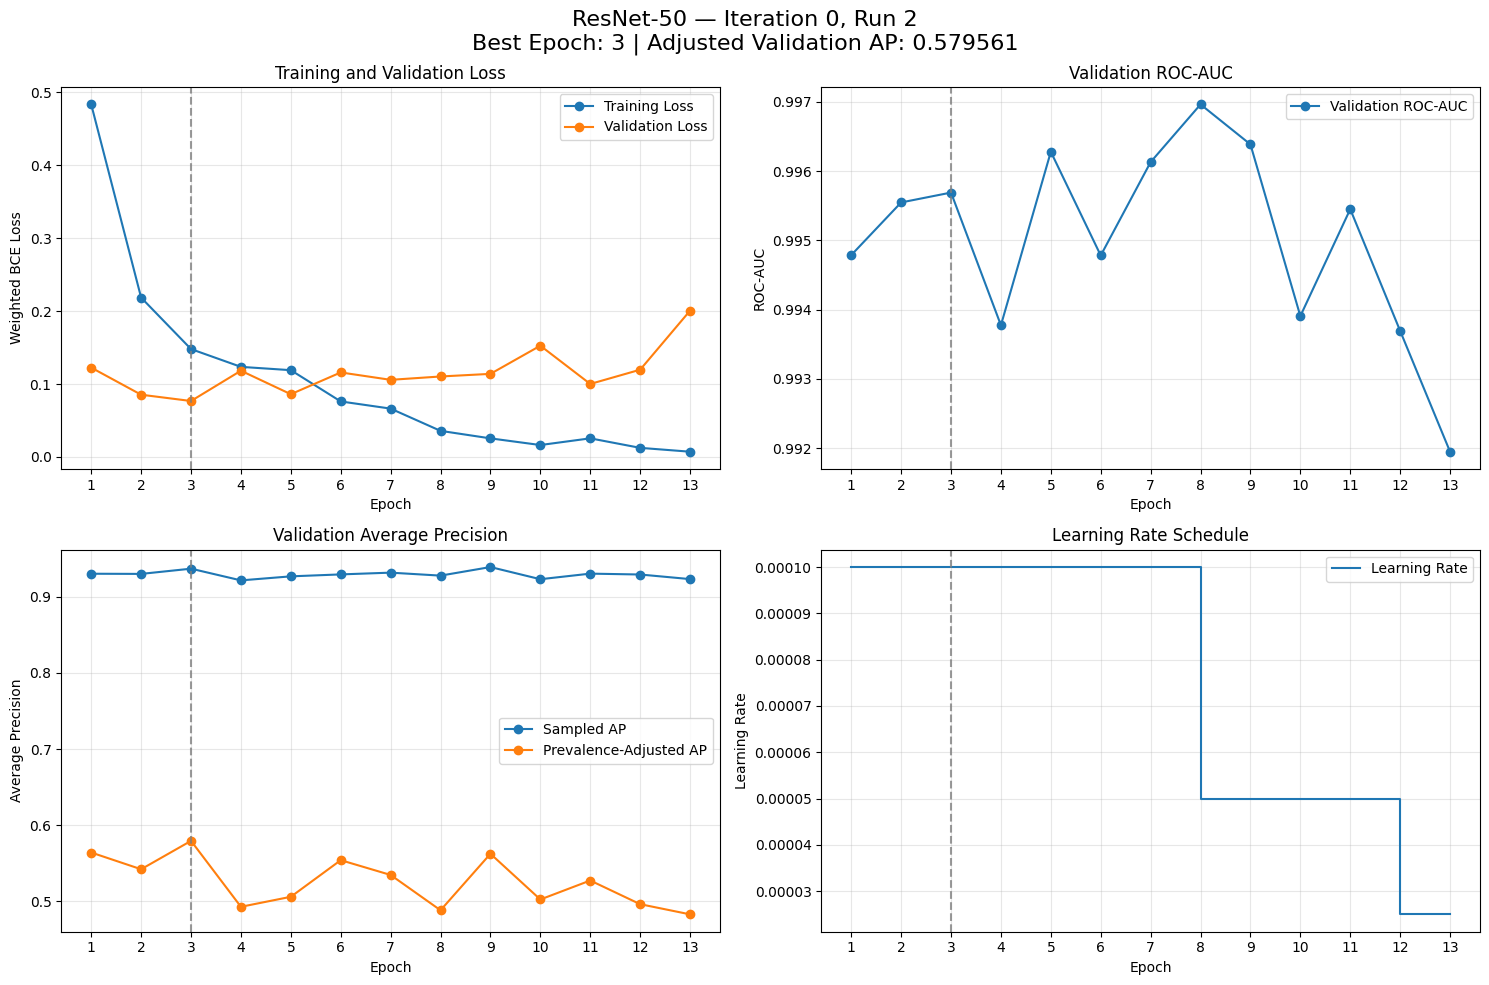

Diagnostics saved: /content/drive/MyDrive/wildfire_resnet/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_diagnostics.png


In [ ]:
# ResNet-50 Training Diagnostics

import matplotlib.pyplot as plt

epochs = np.arange(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Training and validation loss
axes[0, 0].plot(
    epochs, history["train_loss"],
    marker="o", label="Training Loss"
)

axes[0, 0].plot(
    epochs, history["val_loss"],
    marker="o", label="Validation Loss"
)

axes[0, 0].set_title("Training and Validation Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Weighted BCE Loss")
axes[0, 0].legend()

# Validation ROC-AUC
axes[0, 1].plot(
    epochs, history["val_roc_auc"],
    marker="o", label="Validation ROC-AUC"
)

axes[0, 1].set_title("Validation ROC-AUC")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("ROC-AUC")
axes[0, 1].legend()

# Validation Average Precision
axes[1, 0].plot(
    epochs, history["val_pr_auc"],
    marker="o", label="Sampled AP"
)

axes[1, 0].plot(
    epochs, history["val_adjusted_pr_auc"],
    marker="o", label="Prevalence-Adjusted AP"
)

axes[1, 0].set_title("Validation Average Precision")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Average Precision")
axes[1, 0].legend()

# Learning rate
axes[1, 1].step(
    epochs, history["learning_rate"],
    where="post", label="Learning Rate"
)

axes[1, 1].set_title("Learning Rate Schedule")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Learning Rate")
axes[1, 1].legend()

# Mark the selected best epoch
for ax in axes.flat:
    ax.axvline(
        best_epoch,
        color="gray",
        linestyle="--",
        alpha=0.8
    )
    ax.set_xticks(epochs)
    ax.grid(alpha=0.3)

fig.suptitle(
    "ResNet-50 — Iteration 0, Run 2\n"
    f"Best Epoch: {best_epoch} | "
    f"Adjusted Validation AP: {best_val_ap:.6f}",
    fontsize=16
)

plt.tight_layout()

diagnostics_path = run_dir / f"{run_name}_diagnostics.png"

plt.savefig(
    diagnostics_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Diagnostics saved:", diagnostics_path)

## Training Results and Observations

The stabilized ResNet-50 experiment successfully completed
13 epochs without encountering numerical instability.

Early stopping was triggered after 10 consecutive epochs
without improvement in prevalence-adjusted validation
Average Precision.

### Best Model Performance

| Metric | Value |
|---|---:|
| Best Epoch | 3 |
| Training Loss | 0.147929 |
| Validation Loss | 0.076734 |
| Validation ROC-AUC | 0.995690 |
| Sampled Validation AP | 0.936933 |
| Adjusted Validation AP | 0.579561 |

### Overfitting Analysis

Training loss continued decreasing beyond epoch 3, while
validation loss generally increased and adjusted validation
AP failed to improve.

This behavior is consistent with overfitting, potentially
related to the model's substantial parameter count relative
to the small spatial input dimensions.

The best-performing checkpoint from epoch 3 is retained
for independent evaluation on the 2024 test dataset.

### Numerical Stability

Compared to Run 1, the stabilized configuration improved
adjusted validation AP from 0.219833 to 0.579561.

The combined use of FP32 precision, a reduced learning rate,
and gradient clipping improved observed training stability.
The individual contributions of these modifications were
not isolated.

## Best Model Selection and Validation Predictions

The checkpoint corresponding to epoch 3 is restored based
on the highest prevalence-adjusted validation Average Precision.

Predictions on the 2023 validation dataset are used to select
an optimal classification threshold before evaluating the
independent 2024 test dataset.

The classification threshold is selected by maximizing
prevalence-adjusted F1-score.

In [ ]:
# Load Best Model and Generate Predictions

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

print("Best model restored.")
print("Selected epoch:", best_epoch)


def generate_predictions(model, loader):

    model.eval()

    all_labels = []
    all_probabilities = []

    with torch.inference_mode():

        for X_batch, y_batch in tqdm(
            loader, desc="Generating Predictions"
        ):

            X_batch = X_batch.to(
                device, non_blocking=True
            )

            # FP32 inference
            logits = model(X_batch.float())

            assert torch.isfinite(logits).all().item()

            probabilities = torch.sigmoid(logits)

            all_probabilities.append(
                probabilities.cpu().numpy().ravel()
            )

            all_labels.append(
                y_batch.cpu().numpy().ravel()
            )

    y_true = np.concatenate(all_labels)
    y_prob = np.concatenate(all_probabilities)

    assert len(y_true) == len(loader.dataset)
    assert np.isfinite(y_prob).all()

    return y_true, y_prob


# Generate 2023 validation predictions
y_val_true, y_val_prob = generate_predictions(
    model,
    val_loader
)

val_weights = np.where(
    y_val_true == 1,
    1.0,
    20.0
)

print("\n--- Best Model Validation Results ---")

print("Observations:", len(y_val_true))

print(
    "ROC-AUC:",
    roc_auc_score(y_val_true, y_val_prob)
)

print(
    "Sampled AP:",
    average_precision_score(y_val_true, y_val_prob)
)

print(
    "Adjusted AP:",
    average_precision_score(
        y_val_true,
        y_val_prob,
        sample_weight=val_weights
    )
)

print("\nValidation predictions ready!")

Best model restored.
Selected epoch: 3


Generating Predictions:   0%|          | 0/5426 [00:00<?, ?it/s]


--- Best Model Validation Results ---
Observations: 1388899
ROC-AUC: 0.9956903095756985
Sampled AP: 0.9369329922394196
Adjusted AP: 0.5795606823748479

Validation predictions ready!


## Classification Threshold Optimization

The classification threshold is optimized using predictions
from the 2023 validation dataset.

The threshold that maximizes prevalence-adjusted F1-score
is selected to balance precision and recall while accounting
for negative class undersampling.

$$
F_1 = 2 \frac{Precision \times Recall}{Precision + Recall}
$$

The selected threshold is fixed before independent evaluation
on the 2024 test dataset to prevent test data leakage.

In [ ]:
# Validation Threshold Optimization

from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Prevalence-adjusted precision-recall curve
precision, recall, thresholds = precision_recall_curve(
    y_val_true,
    y_val_prob,
    sample_weight=val_weights
)

# Calculate F1 for every available threshold
f1_scores = np.divide(
    2 * precision[:-1] * recall[:-1],
    precision[:-1] + recall[:-1],
    out=np.zeros_like(precision[:-1]),
    where=(precision[:-1] + recall[:-1]) > 0
)

best_idx = np.argmax(f1_scores)

best_threshold = float(thresholds[best_idx])

# Apply selected threshold
y_val_pred = (
    y_val_prob >= best_threshold
).astype(int)

# Sampled classification metrics
sampled_metrics = {
    "precision": float(
        precision_score(y_val_true, y_val_pred)
    ),
    "recall": float(
        recall_score(y_val_true, y_val_pred)
    ),
    "f1": float(
        f1_score(y_val_true, y_val_pred)
    )
}

# Prevalence-adjusted classification metrics
adjusted_metrics = {
    "precision": float(
        precision_score(
            y_val_true, y_val_pred,
            sample_weight=val_weights
        )
    ),
    "recall": float(
        recall_score(
            y_val_true, y_val_pred,
            sample_weight=val_weights
        )
    ),
    "f1": float(
        f1_score(
            y_val_true, y_val_pred,
            sample_weight=val_weights
        )
    )
}

sampled_cm = confusion_matrix(
    y_val_true, y_val_pred
)

adjusted_cm = confusion_matrix(
    y_val_true, y_val_pred,
    sample_weight=val_weights
)

print("--- Optimal Validation Threshold ---")
print(f"Threshold: {best_threshold:.10f}")

print("\n--- Sampled Validation Metrics ---")
for metric, value in sampled_metrics.items():
    print(f"{metric.capitalize()}: {value:.6f}")

print("\n--- Adjusted Validation Metrics ---")
for metric, value in adjusted_metrics.items():
    print(f"{metric.capitalize()}: {value:.6f}")

print("\nSampled Confusion Matrix:")
print(sampled_cm)

print("\nAdjusted Confusion Matrix (Estimated):")
print(adjusted_cm.astype(int))

# Save threshold and validation results
threshold_results = {
    "run_name": run_name,
    "best_epoch": best_epoch,
    "threshold_selection_year": 2023,
    "selection_method": "maximum_adjusted_f1",
    "threshold": best_threshold,
    "sampled_metrics": sampled_metrics,
    "adjusted_metrics": adjusted_metrics,
    "sampled_confusion_matrix": sampled_cm.tolist(),
    "adjusted_confusion_matrix": adjusted_cm.tolist()
}

threshold_path = (
    run_dir / f"{run_name}_threshold.json"
)

with open(threshold_path, "w") as f:
    json.dump(threshold_results, f, indent=4)

print("\nThreshold saved:", threshold_path)

--- Optimal Validation Threshold ---
Threshold: 0.9997940660

--- Sampled Validation Metrics ---
Precision: 0.963431
Recall: 0.582106
F1: 0.725727

--- Adjusted Validation Metrics ---
Precision: 0.568460
Recall: 0.582106
F1: 0.575202

Sampled Confusion Matrix:
[[1385152      81]
 [   1532    2134]]

Adjusted Confusion Matrix (Estimated):
[[27703040     1620]
 [    1532     2134]]

Threshold saved: /content/drive/MyDrive/wildfire_resnet/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_threshold.json


## Independent Test Evaluation — 2024

The best ResNet-50 checkpoint from epoch 3 is evaluated
on the held-out 2024 test dataset.

The classification threshold is fixed using the 2023
validation dataset and is not modified during testing.

Both sampled and prevalence-adjusted metrics are reported
to account for negative class undersampling.

No model parameters are updated during this evaluation.

In [ ]:
# Independent 2024 Test Evaluation

test_dataset = MemoryMappedWildfireDataset(
    tensor_dir / "X_test.npy",
    tensor_dir / "y_test.npy"
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

# Verify test distribution
test_positives = int(test_dataset.y.sum())
test_negatives = len(test_dataset) - test_positives

print("Test observations:", len(test_dataset))
print("Test positives:", test_positives)
print("Test negatives:", test_negatives)
print("Test batches:", len(test_loader))

# Explicitly restore the selected model
model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device,
        weights_only=True
    )
)

model.eval()

# Load the validation-selected threshold
with open(threshold_path, "r") as f:
    saved_threshold = json.load(f)

best_threshold = saved_threshold["threshold"]

print("\nSelected model epoch:", best_epoch)
print("Fixed threshold:", best_threshold)

# Generate independent test predictions
y_test_true, y_test_prob = generate_predictions(
    model,
    test_loader
)

# Apply fixed validation threshold
y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)

# Correct approximately for negative undersampling
test_weights = np.where(
    y_test_true == 1,
    1.0,
    20.0
)

# Sampled test metrics
test_sampled_metrics = {
    "roc_auc": float(
        roc_auc_score(y_test_true, y_test_prob)
    ),
    "average_precision": float(
        average_precision_score(y_test_true, y_test_prob)
    ),
    "precision": float(
        precision_score(y_test_true, y_test_pred)
    ),
    "recall": float(
        recall_score(y_test_true, y_test_pred)
    ),
    "f1": float(
        f1_score(y_test_true, y_test_pred)
    )
}

# Prevalence-adjusted test metrics
test_adjusted_metrics = {
    "roc_auc": float(
        roc_auc_score(
            y_test_true, y_test_prob,
            sample_weight=test_weights
        )
    ),
    "average_precision": float(
        average_precision_score(
            y_test_true, y_test_prob,
            sample_weight=test_weights
        )
    ),
    "precision": float(
        precision_score(
            y_test_true, y_test_pred,
            sample_weight=test_weights
        )
    ),
    "recall": float(
        recall_score(
            y_test_true, y_test_pred,
            sample_weight=test_weights
        )
    ),
    "f1": float(
        f1_score(
            y_test_true, y_test_pred,
            sample_weight=test_weights
        )
    )
}

# Confusion matrices
test_sampled_cm = confusion_matrix(
    y_test_true,
    y_test_pred
)

test_adjusted_cm = confusion_matrix(
    y_test_true,
    y_test_pred,
    sample_weight=test_weights
)

print("\n--- Sampled 2024 Test Metrics ---")

for metric, value in test_sampled_metrics.items():
    print(f"{metric}: {value:.6f}")

print("\n--- Adjusted 2024 Test Metrics ---")

for metric, value in test_adjusted_metrics.items():
    print(f"{metric}: {value:.6f}")

print("\nSampled Test Confusion Matrix:")
print(test_sampled_cm)

print("\nAdjusted Test Confusion Matrix (Estimated):")
print(test_adjusted_cm.astype(int))

# Save final test results
test_results = {
    "run_name": run_name,
    "best_epoch": best_epoch,
    "test_year": 2024,
    "threshold_selection_year": 2023,
    "threshold": best_threshold,
    "test_observations": len(y_test_true),
    "test_positives": test_positives,
    "test_negatives": test_negatives,
    "negative_sample_fraction": 0.05,
    "sampled_metrics": test_sampled_metrics,
    "adjusted_metrics": test_adjusted_metrics,
    "sampled_confusion_matrix": test_sampled_cm.tolist(),
    "adjusted_confusion_matrix": test_adjusted_cm.tolist()
}

test_metrics_path = (
    run_dir / f"{run_name}_test_metrics.json"
)

with open(test_metrics_path, "w") as f:
    json.dump(test_results, f, indent=4)

print("\nTest metrics saved:", test_metrics_path)

print("\nIndependent 2024 testing complete!")

Test observations: 1392854
Test positives: 3841
Test negatives: 1389013
Test batches: 5441

Selected model epoch: 3
Fixed threshold: 0.999794065952301


Generating Predictions:   0%|          | 0/5441 [00:00<?, ?it/s]


--- Sampled 2024 Test Metrics ---
roc_auc: 0.995907
average_precision: 0.928325
precision: 0.954098
recall: 0.530331
f1: 0.681727

--- Adjusted 2024 Test Metrics ---
roc_auc: 0.995907
average_precision: 0.526790
precision: 0.509632
recall: 0.530331
f1: 0.519775

Sampled Test Confusion Matrix:
[[1388915      98]
 [   1804    2037]]

Adjusted Test Confusion Matrix (Estimated):
[[27778300     1960]
 [    1804     2037]]

Test metrics saved: /content/drive/MyDrive/wildfire_resnet/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_test_metrics.json

Independent 2024 testing complete!


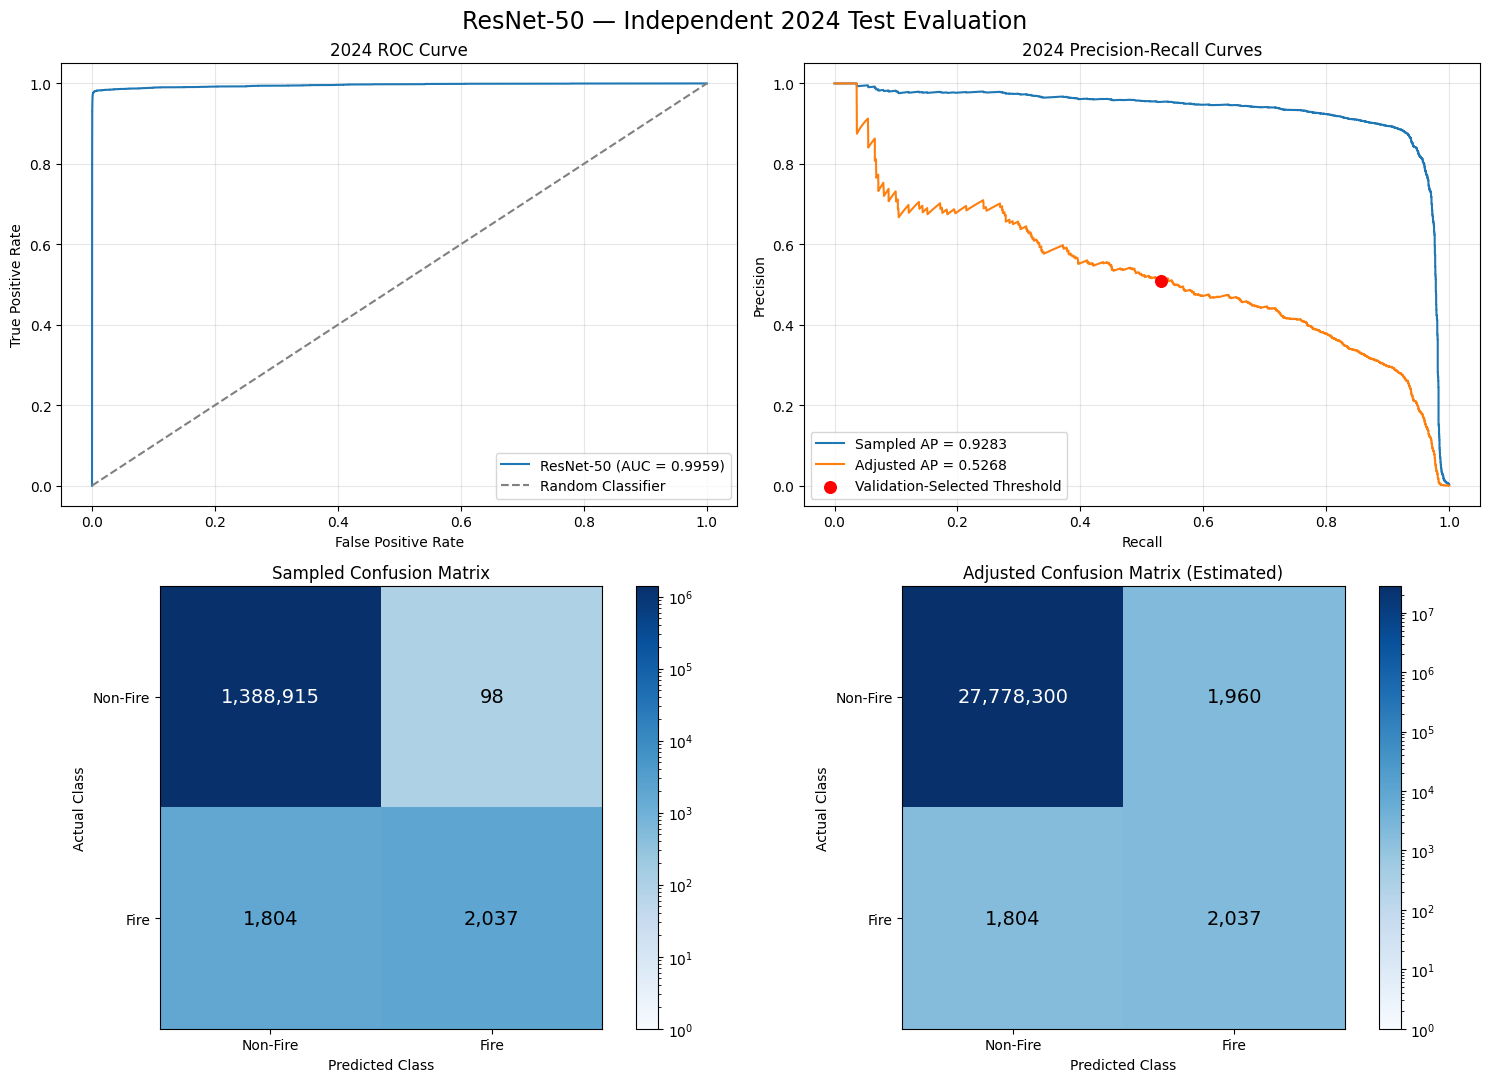

Test diagnostics saved: /content/drive/MyDrive/wildfire_resnet/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_test_diagnostics.png


In [ ]:
# Final Test Evaluation Visualizations

from sklearn.metrics import roc_curve
from matplotlib.colors import LogNorm

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. ROC curve
fpr, tpr, _ = roc_curve(
    y_test_true,
    y_test_prob
)

axes[0, 0].plot(
    fpr,
    tpr,
    label=f"ResNet-50 (AUC = {test_sampled_metrics['roc_auc']:.4f})"
)

axes[0, 0].plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

axes[0, 0].set_title("2024 ROC Curve")
axes[0, 0].set_xlabel("False Positive Rate")
axes[0, 0].set_ylabel("True Positive Rate")
axes[0, 0].legend()


# 2. Precision-recall curves
sampled_precision, sampled_recall, _ = (
    precision_recall_curve(
        y_test_true,
        y_test_prob
    )
)

adjusted_precision, adjusted_recall, _ = (
    precision_recall_curve(
        y_test_true,
        y_test_prob,
        sample_weight=test_weights
    )
)

axes[0, 1].plot(
    sampled_recall,
    sampled_precision,
    label=(
        f"Sampled AP = "
        f"{test_sampled_metrics['average_precision']:.4f}"
    )
)

axes[0, 1].plot(
    adjusted_recall,
    adjusted_precision,
    label=(
        f"Adjusted AP = "
        f"{test_adjusted_metrics['average_precision']:.4f}"
    )
)

# Fixed classification threshold operating point
axes[0, 1].scatter(
    test_adjusted_metrics["recall"],
    test_adjusted_metrics["precision"],
    color="red",
    s=70,
    zorder=5,
    label="Validation-Selected Threshold"
)

axes[0, 1].set_title("2024 Precision-Recall Curves")
axes[0, 1].set_xlabel("Recall")
axes[0, 1].set_ylabel("Precision")
axes[0, 1].legend()


# 3. Sampled and adjusted confusion matrices
matrices = [
    (
        axes[1, 0],
        test_sampled_cm,
        "Sampled Confusion Matrix"
    ),
    (
        axes[1, 1],
        test_adjusted_cm.astype(int),
        "Adjusted Confusion Matrix (Estimated)"
    )
]

for ax, cm, title in matrices:

    image = ax.imshow(
        cm,
        cmap="Blues",
        norm=LogNorm(
            vmin=1,
            vmax=cm.max()
        )
    )

    for i in range(2):
        for j in range(2):

            ax.text(
                j, i,
                f"{cm[i, j]:,}",
                ha="center",
                va="center",
                fontsize=14,
                color=(
                    "white"
                    if image.norm(cm[i, j]) > 0.6
                    else "black"
                )
            )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["Non-Fire", "Fire"])
    ax.set_yticklabels(["Non-Fire", "Fire"])

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.set_title(title)

    fig.colorbar(image, ax=ax)


axes[0, 0].grid(alpha=0.3)
axes[0, 1].grid(alpha=0.3)

fig.suptitle(
    "ResNet-50 — Independent 2024 Test Evaluation",
    fontsize=17
)

plt.tight_layout()

test_diagnostics_path = (
    run_dir / f"{run_name}_test_diagnostics.png"
)

plt.savefig(
    test_diagnostics_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Test diagnostics saved:", test_diagnostics_path)

## Independent 2024 Test Results

The selected ResNet-50 checkpoint from epoch 3 was
evaluated on 1,392,854 held-out test observations.

The classification threshold of 0.999794065952301 was
determined exclusively using the 2023 validation dataset.

| Metric | Sampled | Prevalence-Adjusted |
|---|---:|---:|
| ROC-AUC | 0.995907 | 0.995907 |
| Average Precision | 0.928325 | 0.526790 |
| Precision | 0.954098 | 0.509632 |
| Recall | 0.530331 | 0.530331 |
| F1-Score | 0.681727 | 0.519775 |

### Generalization Analysis

Prevalence-adjusted Average Precision decreased from
0.579561 during validation to 0.526790 during testing.

The model retained substantial predictive performance
on an unseen year, demonstrating temporal generalization
within the available dataset.

### Architectural Comparison

ResNet-50 achieved higher prevalence-adjusted Average
Precision than the previously reported baseline CNN,
although the CNN retained higher ROC-AUC and F1-score.

These results indicate that greater architectural complexity
may improve precision-recall ranking performance without
necessarily improving every classification metric.

### Limitations

Prevalence-adjusted metrics are estimates based on inverse
negative-sampling weights rather than direct evaluation of
the complete unsampled population.

Differences in observation eligibility and threshold
selection must be considered when comparing deep learning
models with traditional machine learning models.

## Prediction Exports

Validation and test predictions are exported for downstream
evaluation and comparative analysis.

Each export contains:

- Tensor row index
- Ground truth label
- Predicted sigmoid score
- Predicted binary class
- Prevalence-adjustment weight

The classification threshold is selected using the 2023
validation dataset and remains fixed for 2024 testing.

Tensor row indices preserve the original observation order
within each spatial tensor dataset.

In [ ]:
# Export Validation and Test Predictions

import pandas as pd

prediction_exports = [
    (2023, y_val_true, y_val_prob, val_weights),
    (2024, y_test_true, y_test_prob, test_weights)
]

for year, labels, probabilities, weights in prediction_exports:

    predictions_df = pd.DataFrame({
        "tensor_index": np.arange(
            len(labels), dtype=np.int32
        ),
        "y_true": labels.astype(np.int8),
        "y_prob": probabilities.astype(np.float32),
        "y_pred": (
            probabilities >= best_threshold
        ).astype(np.int8),
        "sample_weight": weights.astype(np.float32)
    })

    export_path = (
        run_dir / f"{run_name}_{year}_predictions.parquet"
    )

    predictions_df.to_parquet(
        export_path,
        index=False,
        compression="snappy"
    )

    print(f"\n{year} predictions exported!")
    print("Shape:", predictions_df.shape)
    print(f"Size: {export_path.stat().st_size / 1e6:.2f} MB")
    print("Path:", export_path)

    print(predictions_df.head())

    del predictions_df

print("\nAll prediction exports complete!")


2023 predictions exported!
Shape: (1388899, 5)
Size: 13.38 MB
Path: /content/drive/MyDrive/wildfire_resnet/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_2023_predictions.parquet
   tensor_index  y_true        y_prob  y_pred  sample_weight
0             0       1  2.742879e-08       0            1.0
1             1       1  2.572787e-08       0            1.0
2             2       1  9.975891e-01       0            1.0
3             3       1  9.999126e-01       1            1.0
4             4       0  7.912311e-05       0           20.0

2024 predictions exported!
Shape: (1392854, 5)
Size: 13.41 MB
Path: /content/drive/MyDrive/wildfire_resnet/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_2024_predictions.parquet
   tensor_index  y_true    y_prob  y_pred  sample_weight
0             0       1  0.998956       0            1.0
1             1       1  0.999911       1            1.0
2             2       0  0.000015       0           20.0
3           

In [ ]:
# Final Experiment Summary

experiment_summary = {
    "model": "ResNet-50",
    "iteration": 0,
    "selected_run": 2,
    "seed": SEED,
    "total_parameters": sum(
        p.numel() for p in model.parameters()
    ),
    "trainable_parameters": sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    ),
    "pretrained": False,
    "frozen_layers": False,

    "training": {
        "configuration": config,
        "completed_epochs": len(history["train_loss"]),
        "best_epoch": best_epoch,
        "early_stopping": True,
        "total_training_minutes": sum(
            history["epoch_seconds"]
        ) / 60
    },

    "validation_2023": {
        "observations": len(y_val_true),
        "roc_auc": float(
            roc_auc_score(y_val_true, y_val_prob)
        ),
        "sampled_average_precision": float(
            average_precision_score(
                y_val_true, y_val_prob
            )
        ),
        "adjusted_average_precision": best_val_ap,
        "threshold": best_threshold,
        "sampled_metrics": sampled_metrics,
        "adjusted_metrics": adjusted_metrics
    },

    "testing_2024": test_results,

    "previous_run": run1_summary,

    "limitations": [
        "Adjusted metrics estimate population performance "
        "using inverse negative-sampling weights.",

        "Sigmoid scores are not calibrated probabilities.",

        "Spatial tensors do not retain cell IDs or dates.",

        "Classical ML and deep learning datasets differ "
        "in sampling and observation eligibility.",

        "Individual effects of learning rate, FP32 precision "
        "and gradient clipping were not isolated.",

        "Temporal availability of vegetation composites "
        "and terrain feature alignment require verification.",

        "Only one random seed was evaluated."
    ]
}

summary_path = run_dir / f"{run_name}_summary.json"

with open(summary_path, "w") as f:
    json.dump(experiment_summary, f, indent=4)

print(json.dumps(experiment_summary, indent=4))

print("\nFinal experiment summary saved!")
print("Path:", summary_path)

{
    "model": "ResNet-50",
    "iteration": 0,
    "selected_run": 2,
    "seed": 4337,
    "total_parameters": 23505857,
    "trainable_parameters": 23505857,
    "pretrained": false,
    "frozen_layers": false,
    "training": {
        "configuration": {
            "model": "WildfireResNet50",
            "iteration": 0,
            "run": "run2_seeded",
            "seed": 4337,
            "epochs": 50,
            "batch_size": 256,
            "learning_rate": 0.0001,
            "weight_decay": 0.0001,
            "pos_weight": 153.549889135255,
            "early_stopping_patience": 10,
            "validation_negative_sample_fraction": 0.05,
            "optimizer": "AdamW",
            "scheduler": "ReduceLROnPlateau",
            "pretrained": false,
            "mixed_precision": false,
            "training_samples": 557616,
            "validation_samples": 1388899,
            "torch_version": "2.14.1+cu130",
            "torchvision_version": "0.29.1+cu130",
        

In [ ]:
# Final Artifact Verification

print("Experiment:", run_name)
print("Directory:", run_dir)

total_bytes = 0

for path in sorted(run_dir.iterdir()):

    if path.is_file():

        size = path.stat().st_size
        total_bytes += size

        print(f"{path.name:<65} {size / 1e6:>8.2f} MB")

print("-" * 80)

print(f"Total artifact size: {total_bytes / 1e6:.2f} MB")

Experiment: resnet50_iteration0_run2_seeded
Directory: /content/drive/MyDrive/wildfire_resnet/resnet50_iteration0_run2_seeded
config.json                                                           0.00 MB
resnet50_iteration0_run2_seeded_2023_predictions.parquet             13.38 MB
resnet50_iteration0_run2_seeded_2024_predictions.parquet             13.41 MB
resnet50_iteration0_run2_seeded_best.pth                             94.36 MB
resnet50_iteration0_run2_seeded_diagnostics.png                       0.57 MB
resnet50_iteration0_run2_seeded_latest.pth                          282.58 MB
resnet50_iteration0_run2_seeded_summary.json                          0.00 MB
resnet50_iteration0_run2_seeded_test_diagnostics.png                  0.47 MB
resnet50_iteration0_run2_seeded_test_metrics.json                     0.00 MB
resnet50_iteration0_run2_seeded_threshold.json                        0.00 MB
resnet50_iteration0_run2_seeded_validation_metrics.json               0.00 MB
----------------

## Conclusion

A modified ResNet-50 architecture was implemented for
next-day wildfire ignition prediction using nine environmental
features represented as 7×7 spatial patches.

The network was trained from scratch with all 23,505,857
parameters remaining trainable.

The initial mixed-precision experiment encountered numerical
instability. A second experiment using FP32 precision,
a reduced learning rate, and gradient clipping successfully
completed training.

Early stopping terminated the second experiment after
13 epochs, retaining the best checkpoint from epoch 3.

### Final Performance

| Metric | 2023 Validation | 2024 Testing |
|---|---:|---:|
| ROC-AUC | 0.995690 | 0.995907 |
| Sampled AP | 0.936933 | 0.928325 |
| Adjusted AP | 0.579561 | 0.526790 |
| Adjusted Precision | 0.568460 | 0.509632 |
| Recall | 0.582106 | 0.530331 |
| Adjusted F1 | 0.575202 | 0.519775 |

ResNet-50 achieved higher reported prevalence-adjusted
Average Precision than the baseline CNN, while the CNN
retained higher ROC-AUC and F1-score.

The results demonstrate that deeper residual architectures
can provide competitive wildfire prediction performance,
although increased architectural complexity introduces
computational costs and susceptibility to overfitting.

Further experiments with ResNet-101 and ResNet-152 will
investigate the relationship between network depth,
computational complexity, and predictive performance.

In [ ]:
# Package Lightweight GitHub Artifacts

import zipfile

artifact_root = (
    Path("/content/drive/MyDrive") / "wildfire_resnet"
)

github_zip = (
    artifact_root / "resnet50_github_artifacts.zip"
)

with zipfile.ZipFile(
    github_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as z:

    for run_folder in [
        "resnet50_iteration0_run1_seeded",
        "resnet50_iteration0_run2_seeded"
    ]:

        source_dir = artifact_root / run_folder

        assert source_dir.is_dir(), source_dir

        for path in sorted(source_dir.iterdir()):

            if path.is_file() and path.suffix in [
                ".json", ".png"
            ]:

                archive_name = (
                    Path("resnet50")
                    / run_folder
                    / path.name
                )

                z.write(path, archive_name)

                print("Added:", archive_name)

print("\nGitHub artifact package created!")
print("Path:", github_zip)
print(f"Size: {github_zip.stat().st_size / 1e6:.2f} MB")

Added: resnet50/resnet50_iteration0_run1_seeded/config.json
Added: resnet50/resnet50_iteration0_run1_seeded/resnet50_iteration0_run1_seeded_validation_metrics.json
Added: resnet50/resnet50_iteration0_run1_seeded/run_summary.json
Added: resnet50/resnet50_iteration0_run2_seeded/config.json
Added: resnet50/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_diagnostics.png
Added: resnet50/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_summary.json
Added: resnet50/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_test_diagnostics.png
Added: resnet50/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_test_metrics.json
Added: resnet50/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_threshold.json
Added: resnet50/resnet50_iteration0_run2_seeded/resnet50_iteration0_run2_seeded_validation_metrics.json

GitHub artifact package created!
Path: /content/drive/MyDrive/wildfire_resnet/resnet50_github_artifacts.zip
Size: 0.88 MB
